## Làm sạch dữ liệu

In [2]:
import pandas as pd
import numpy as np, re
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import KFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from scipy.sparse import hstack
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor

In [3]:
# 1. Tải dữ liệu từ file csv
# Giả sử bạn đã upload file có tên là 'anime-filtered.csv' vào cùng thư mục với script này.
try:
    df = pd.read_csv('anime-filtered.csv')
    print("Dữ liệu đã được tải thành công!")
    print(df.head()) # Hiển thị 5 hàng đầu tiên để kiểm tra sơ bộ
except FileNotFoundError:
    print("Không tìm thấy file 'anime-filtered.csv'. Vui lòng kiểm tra lại đường dẫn.")
    # Exit script nếu không tìm thấy file để tránh lỗi sau này.
    exit()


# 2. Xử lý giá trị bị thiếu (Missing Values)
# Kiểm tra tổng số giá trị thiếu trong từng cột
print("\nSố lượng giá trị thiếu trong mỗi cột:")
print(df.isnull().sum())

# Giả sử cột target là 'rating' và chúng ta muốn xóa các hàng thiếu 'rating'.
df = df.dropna(subset=['Rating'])

# Với các cột phân loại khác có giá trị thiếu, ví dụ 'genre',
# chúng ta có thể thay bằng 'Unknown'.
if 'genre' in df.columns:
    df['genre'] = df['genre'].fillna('Unknown')


# 3. Chuyển đổi kiểu dữ liệu
# Ví dụ, nếu cột 'scored_by' chứa số lượng người đánh giá nhưng đang ở dạng object, 
# chúng ta cần chuyển nó thành số. 'coerce' sẽ biến các giá trị không hợp lệ thành NaN.
if 'scored_by' in df.columns:
    df['scored_by'] = pd.to_numeric(df['scored_by'], errors='coerce')


# 4. Loại bỏ các giá trị trùng lặp
df = df.drop_duplicates()

# 5. Kiểm tra lại dữ liệu sau khi làm sạch
print("\nThông tin dữ liệu sau khi làm sạch:")
print(df.info())
print("\nSố lượng giá trị thiếu sau khi làm sạch:")
print(df.isnull().sum())

print("\n\nDữ liệu sau khi làm sạch:")
print(df.head())

# 6. (Tùy chọn) Lưu dữ liệu đã làm sạch vào file mới
df.to_csv('cleaned_anime_data.csv', index=False)
print("\nDữ liệu đã làm sạch đã được lưu vào 'cleaned_anime_data.csv'")

Dữ liệu đã được tải thành công!
   anime_id                             Name  Score  \
0         1                     Cowboy Bebop   8.78   
1         5  Cowboy Bebop: Tengoku no Tobira   8.39   
2         6                           Trigun   8.24   
3         7               Witch Hunter Robin   7.27   
4         8                   Bouken Ou Beet   6.98   

                                              Genres            English name  \
0    Action, Adventure, Comedy, Drama, Sci-Fi, Space            Cowboy Bebop   
1              Action, Drama, Mystery, Sci-Fi, Space  Cowboy Bebop:The Movie   
2  Action, Sci-Fi, Adventure, Comedy, Drama, Shounen                  Trigun   
3  Action, Mystery, Police, Supernatural, Drama, ...      Witch Hunter Robin   
4          Adventure, Fantasy, Shounen, Supernatural  Beet the Vandel Buster   

                      Japanese name  \
0                         カウボーイビバップ   
1                    カウボーイビバップ 天国の扉   
2                             トライガン   


## Lọc cột 'Type' và giữ lại định dạng 'TV'

In [4]:
# Thiết lập giao diện cho biểu đồ đẹp hơn
sns.set_theme(style="whitegrid")

# Lọc cột Type chỉ giữ lại định dạng 'TV' 
# Kiểm tra số lượng các định dạng trước khi lọc (để đối chiếu)
print("Số lượng các định dạng trước khi lọc:")
print(df['Type'].value_counts())

# Lọc dữ liệu
df_tv = df[df['Type'] == 'TV'].copy()

print(f"\nSố lượng dòng sau khi lọc chỉ giữ định dạng 'TV': {df_tv.shape[0]}")

Số lượng các định dạng trước khi lọc:
Type
TV         4650
OVA        3364
Movie      2636
Special    1991
ONA        1531
Music       744
Unknown      36
Name: count, dtype: int64

Số lượng dòng sau khi lọc chỉ giữ định dạng 'TV': 4650


## Khảo sát phân phối của Score và Episodes

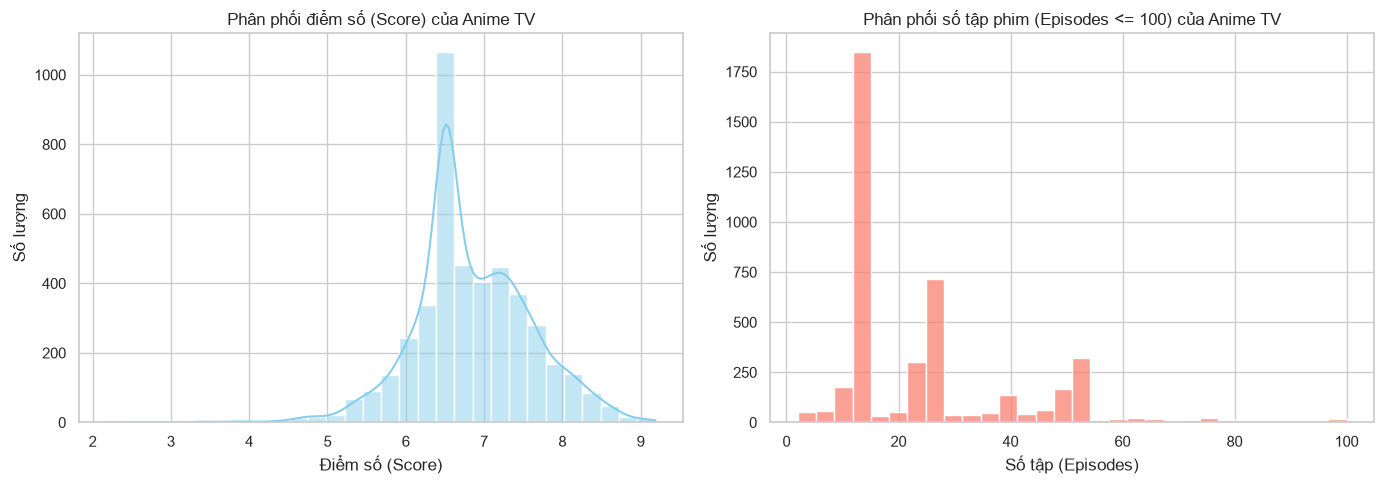


Thống kê mô tả của cột Score và Episodes:
             Score     Episodes
count  4423.000000  4423.000000
mean      6.843418    34.000678
std       0.741595    87.969053
min       2.180000     2.000000
25%       6.480000    12.000000
50%       6.710000    21.000000
75%       7.330000    35.000000
max       9.190000  3057.000000


In [5]:
# Khảo sát phân phối của Score và Episodes

# Chuẩn bị dữ liệu cho cột 'Episodes' (vì đôi khi có giá trị 'Unknown' hoặc kiểu chuỗi)
df_tv['Episodes'] = pd.to_numeric(df_tv['Episodes'], errors='coerce')
df_tv['Score'] = pd.to_numeric(df_tv['Score'], errors='coerce')

# Xóa bỏ các dòng bị thiếu dữ liệu ở 2 cột này để vẽ biểu đồ chính xác
df_tv = df_tv.dropna(subset=['Score', 'Episodes'])

# Tạo khung vẽ gồm 2 biểu đồ nằm cạnh nhau
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Phân phối của Score
sns.histplot(df_tv['Score'], bins=30, kde=True, ax=axes[0], color='skyblue')
axes[0].set_title('Phân phối điểm số (Score) của Anime TV')
axes[0].set_xlabel('Điểm số (Score)')
axes[0].set_ylabel('Số lượng')

# Biểu đồ 2: Phân phối của Số tập phim (Episodes)
# Để biểu đồ dễ nhìn, chúng ta có thể giới hạn số tập khảo sát dưới 100 tập.
df_filtered_episodes = df_tv[df_tv['Episodes'] <= 100]

sns.histplot(df_filtered_episodes['Episodes'], bins=30, kde=False, ax=axes[1], color='salmon')
axes[1].set_title('Phân phối số tập phim (Episodes <= 100) của Anime TV')
axes[1].set_xlabel('Số tập (Episodes)')
axes[1].set_ylabel('Số lượng')

# Hiển thị biểu đồ lên màn hình
plt.tight_layout()
plt.show()

# In ra các thông số thống kê mô tả cơ bản của 2 cột
print("\nThống kê mô tả của cột Score và Episodes:")
print(df_tv[['Score', 'Episodes']].describe())

## Vẽ 8 biểu đồ

### Bước chuẩn bị

In [6]:
# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

# Đọc dữ liệu (Đã lọc Type == 'TV' từ bước trước)
df = pd.read_csv('anime-filtered.csv')
df_tv = df[df['Type'] == 'TV'].copy()

# Xử lý dữ liệu số sạch sẽ
df_tv['Score'] = pd.to_numeric(df_tv['Score'], errors='coerce')
df_tv['Episodes'] = pd.to_numeric(df_tv['Episodes'], errors='coerce')
df_tv['Popularity'] = pd.to_numeric(df_tv['Popularity'], errors='coerce')
df_tv['Members'] = pd.to_numeric(df_tv['Members'], errors='coerce')
df_tv['Favorites'] = pd.to_numeric(df_tv['Favorites'], errors='coerce')

# Trích xuất năm phát hành (Year) từ cột 'Aired' bằng Regex (Tìm 4 chữ số liên tiếp đầu tiên)
df_tv['Year'] = df_tv['Aired'].str.extract(r'(\d{4})').astype(float)

# Loại bỏ các dòng bị khuyết thông tin cốt lõi để phân tích
df_clean = df_tv.dropna(subset=['Score', 'Episodes', 'Popularity', 'Year', 'Members', 'Favorites']).copy()

### 1. Line chart: Điểm Score trung bình qua các năm

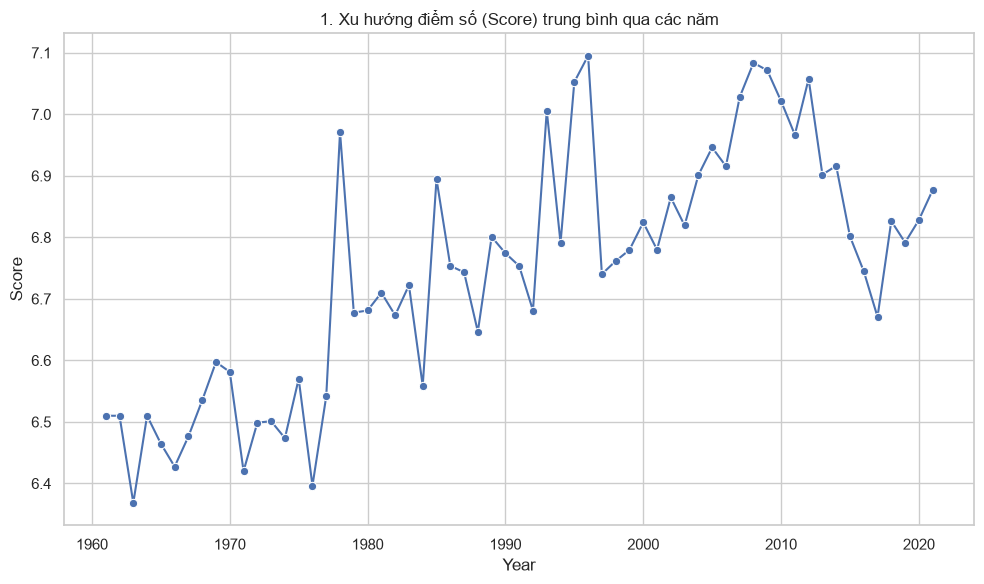

In [7]:
plt.figure(figsize=(10, 6))
year_score = df_clean.groupby('Year')['Score'].mean().reset_index()
sns.lineplot(data=year_score, x='Year', y='Score', marker='o', color='b')
plt.title('1. Xu hướng điểm số (Score) trung bình qua các năm')
plt.tight_layout()
plt.show()

#### Nhìn chung, điểm số (Score) trung bình của Anime TV có xu hướng tăng dần theo thời gian từ năm 1960 đến khoảng năm 2010 (đạt đỉnh gần 7.1), sau đó có dấu hiệu biến động và suy giảm nhẹ trong những năm gần đây.

### 2. Bar chart: Top 10 Studios sản xuất nhiều Anime TV nhất

C:\Users\Admin\AppData\Local\Temp\ipykernel_2576\1464371431.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_studios.values, y=top_studios.index, palette='viridis')


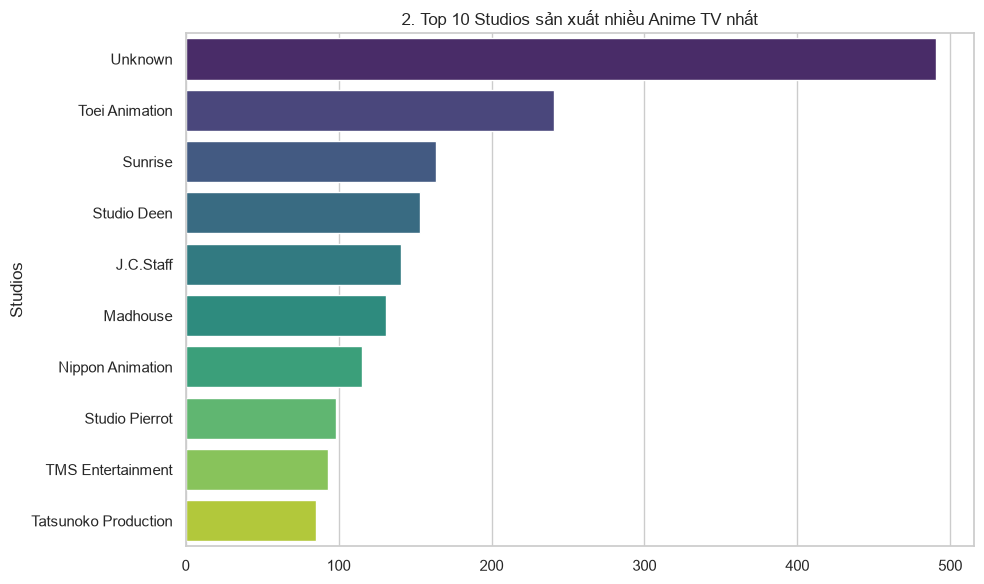

In [8]:
plt.figure(figsize=(10, 6))
top_studios = df_clean['Studios'].value_counts().head(10)
sns.barplot(x=top_studios.values, y=top_studios.index, palette='viridis')
plt.title('2. Top 10 Studios sản xuất nhiều Anime TV nhất')
plt.tight_layout()
plt.show()

#### Ngoại trừ nhóm không rõ danh tính (Unknown) chiếm số lượng áp đảo, Toei Animation là studio dẫn đầu vượt trội về số lượng Anime TV sản xuất, bỏ xa các studio tên tuổi khác trong top 10 như Sunrise hay Studio Deen.

### 3. Scatter plot: Mối quan hệ giữa Độ nổi tiếng (Popularity) và Score

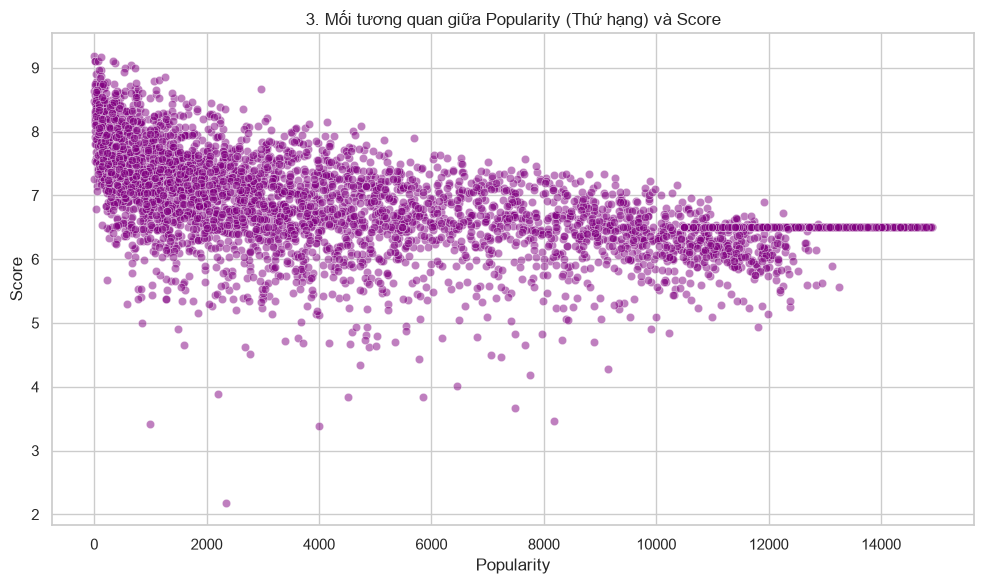

In [9]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_clean, x='Popularity', y='Score', alpha=0.5, color='purple')
plt.title('3. Mối tương quan giữa Popularity (Thứ hạng) và Score')
plt.tight_layout()
plt.show()

#### Biểu đồ trên cho thấy mối tương quan nghịch rõ rệt giữa Popularity và Score, nghĩa là những Anime có thứ hạng phổ biến càng cao (số Popularity càng nhỏ) thì thường có xu hướng sở hữu điểm số trung bình cao hơn và tập trung đậm đặc hơn.

### 4. Bar chart: Điểm Score trung bình theo Nguồn gốc tác phẩm

C:\Users\Admin\AppData\Local\Temp\ipykernel_2576\4092864708.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=source_score, x='Score', y='Source', palette='coolwarm')


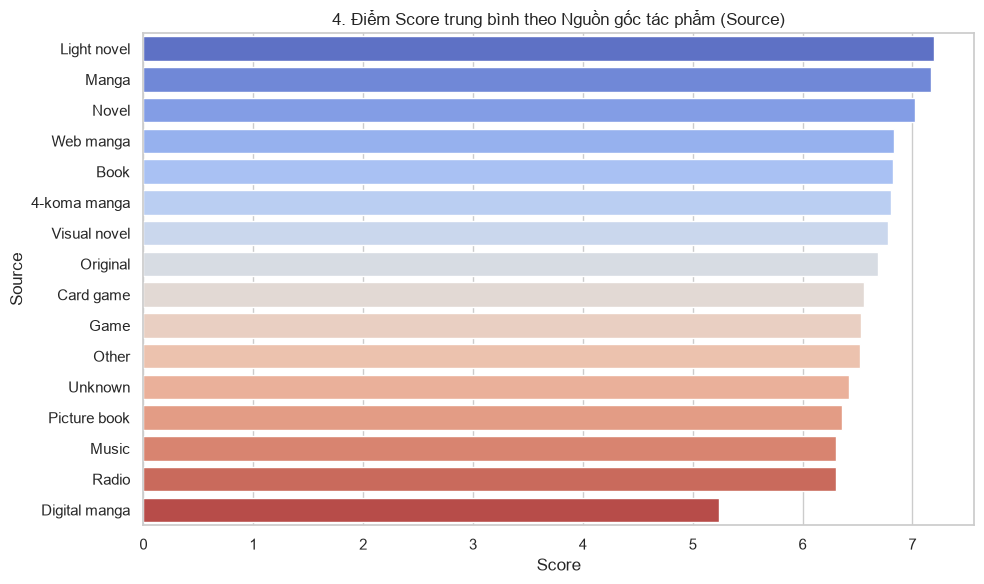

In [10]:
plt.figure(figsize=(10, 6))
source_score = df_clean.groupby('Source')['Score'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=source_score, x='Score', y='Source', palette='coolwarm')
plt.title('4. Điểm Score trung bình theo Nguồn gốc tác phẩm (Source)')
plt.tight_layout()
plt.show()

#### Biểu đồ trên cho thấy các Anime có nguồn gốc từ Light novel và Manga đạt điểm số (Score) trung bình cao nhất, trong khi những tác phẩm chuyển thể từ Digital manga có điểm số trung bình thấp nhất.

### 5. Boxplot: Phân phối điểm số theo Phân loại độ tuổi

C:\Users\Admin\AppData\Local\Temp\ipykernel_2576\1458853575.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Score', y='Rating', palette='Set3')


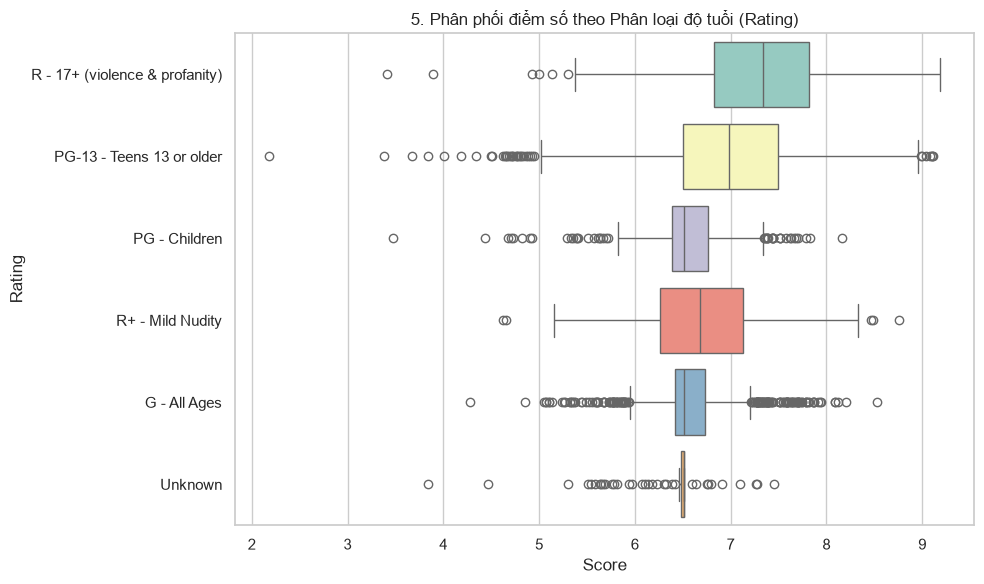

In [11]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x='Score', y='Rating', palette='Set3')
plt.title('5. Phân phối điểm số theo Phân loại độ tuổi (Rating)')
plt.tight_layout()
plt.show()

#### Biểu đồ trên cho thấy phân loại độ tuổi R - 17+ (violence & profanity) có điểm số (Score) trung vị cao nhất và dải điểm phân bố rộng nhất, trong khi nhóm G - All Ages và Unknown có dải điểm tập trung hẹp hơn với xu hướng điểm số thấp hơn.

### 6. Bar chart: Top 10 Anime có lượng Members lớn nhất

C:\Users\Admin\AppData\Local\Temp\ipykernel_2576\1695480776.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_anime_members, x='Members', y='Name', palette='magma')


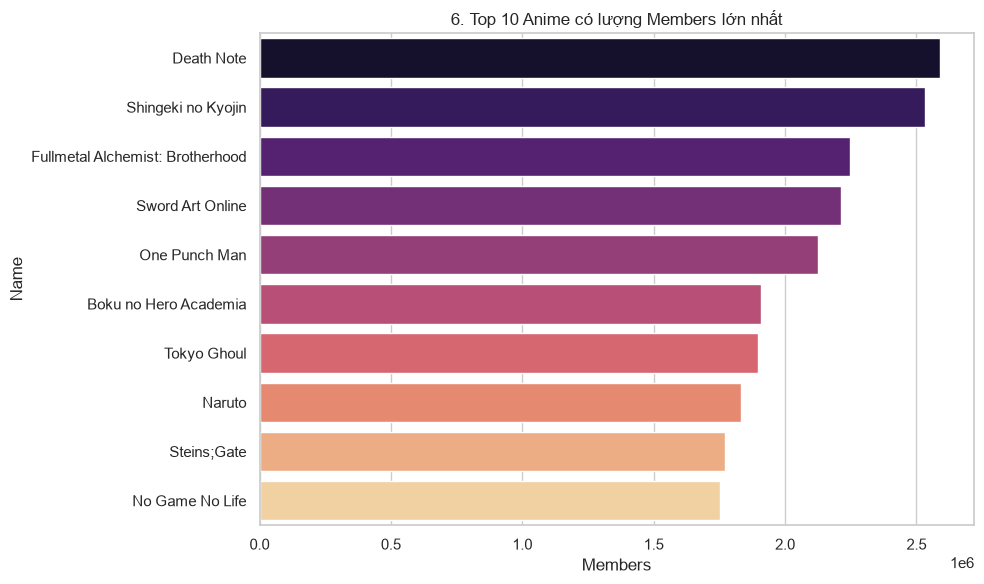

In [12]:
plt.figure(figsize=(10, 6))
top_anime_members = df_clean.sort_values(by='Members', ascending=False).head(10)
sns.barplot(data=top_anime_members, x='Members', y='Name', palette='magma')
plt.title('6. Top 10 Anime có lượng Members lớn nhất')
plt.tight_layout()
plt.show()

#### Biểu đồ trên cho thấy Death Note và Shingeki no Kyojin là hai bộ Anime dẫn đầu vượt trội về lượng người theo dõi (Members) với quy mô đều vượt mốc 2.5 triệu người, bỏ xa các tác phẩm còn lại trong top 10.

### 7. Heatmap: Ma trận tương quan giữa các biến số số học

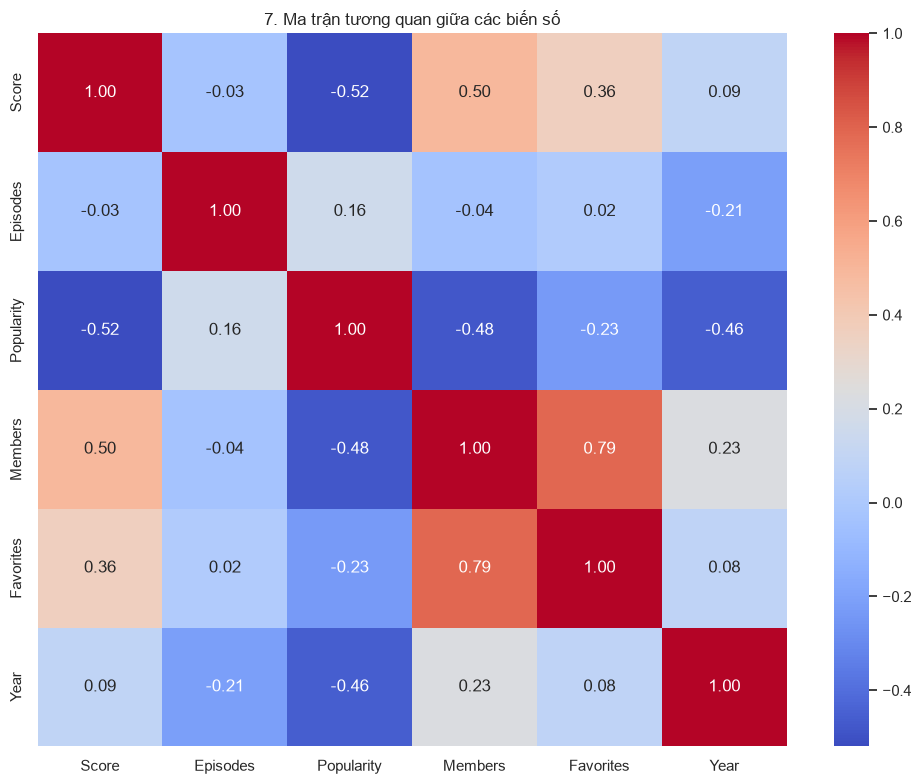

In [13]:
plt.figure(figsize=(10, 8))
corr_matrix = df_clean[['Score', 'Episodes', 'Popularity', 'Members', 'Favorites', 'Year']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('7. Ma trận tương quan giữa các biến số')
plt.tight_layout()
plt.show()

#### Biểu đồ trên cho thấy mối quan hệ tương quan thuận mạnh nhất diễn ra giữa lượng người theo dõi (Members) và lượt yêu thích (Favorites) với hệ số 0.79, trong khi biến Popularity có mối tương quan nghịch rõ rệt với hầu hết các biến số còn lại, đặc biệt là với Score (-0.52).

### 8. Histogram: Phân phối số lượng Anime được sản xuất qua các năm

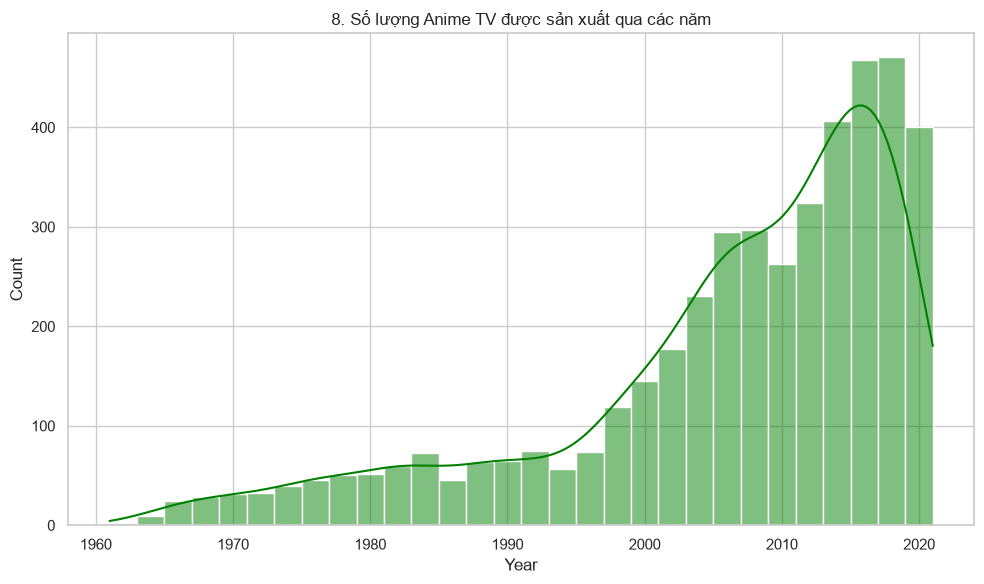

In [14]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_clean, x='Year', bins=30, kde=True, color='green')
plt.title('8. Số lượng Anime TV được sản xuất qua các năm')
plt.tight_layout()
plt.show()

#### Biểu đồ trên cho thấy số lượng Anime TV được sản xuất tăng trưởng liên tục và bùng nổ mạnh mẽ kể từ sau năm 2000, đạt đỉnh cao nhất vào giai đoạn 2015–2020 với gần 500 tác phẩm mỗi năm trước khi có dấu hiệu sụt giảm ngắn hạn ở năm cuối cùng.

## Phân tích xu hướng Anime "Hot"

### Dựa trên các biểu đồ đã vẽ và phân tích dữ liệu, chúng ta đúc kết ra các xu hướng của một bộ Anime thành công (Hot):
- Nguồn gốc tác phẩm (Source): Các bộ anime chuyển thể từ Manga và Light Novel thường chiếm ưu thế áp đảo về cả số lượng lẫn điểm số trung bình (Score) so với các tác phẩm gốc (Original) hoặc chuyển thể từ Game. Điều này là do chúng đã có sẵn một lượng fan hâm mộ hùng hậu từ trước.
- Yếu tố Studio: Những hãng sản xuất lớn như Madhouse, Sunrise, Toei Animation, hay J.C.Staff nắm giữ số lượng tác phẩm đồ sộ và thường xuyên có các bộ Anime lọt top phổ biến cao.
- Mối tương quan ngầm: Biểu đồ Heatmap sẽ chỉ ra rằng Score có mối quan hệ nghịch biến rất mạnh với Popularity Rank (Rank số càng nhỏ - tức vị trí càng cao thì điểm số càng cao) và thuận biến rất mạnh với lượng Members, Favorites. Số tập phim (Episodes) không có sự ảnh hưởng quá lớn đến điểm số cao hay thấp, nhưng những bộ cực dài thường sở hữu lượng fan trung thành lớn.

## Train Model hồi quy dự đoán Score

In [15]:
df_ml = df.copy()
df_ml['Score'] = pd.to_numeric(df_ml['Score'], errors='coerce')
df_ml = df_ml.dropna(subset=['Score'])

for c in ['Members','Favorites','Watching','Completed','On-Hold','Dropped','Popularity']:
    df_ml[c] = pd.to_numeric(df_ml[c], errors='coerce').fillna(0)

df_ml['Episodes'] = pd.to_numeric(df_ml['Episodes'], errors='coerce').fillna(1)

# Year from Premiered/Aired
def get_year(row):
    prem = str(row['Premiered'])
    m = re.search(r'(\d{4})', prem)
    if m: return int(m.group(1))
    aired = str(row['Aired'])
    m = re.search(r'(\d{4})', aired)
    if m: return int(m.group(1))
    return 2020
df_ml['Year'] = df_ml.apply(get_year, axis=1)

df_ml = df_ml[(df_ml["Members"] > 200) & (df_ml["Score"] >= 3.5) & (df_ml["Type"] == "TV")].copy()

df_ml['Studios'] = df_ml['Studios'].fillna('Unknown')
df_ml['Rating'] = df_ml['Rating'].fillna('Unknown')
df_ml['Source'] = df_ml['Source'].fillna('Unknown')
df_ml['Type'] = df_ml['Type'].fillna('Unknown')

# Duration in minutes
def parse_duration(d):
    d = str(d)
    h = re.search(r'(\d+)\s*hr', d)
    m = re.search(r'(\d+)\s*min', d)
    total = 0
    if h: total += int(h.group(1))*60
    if m: total += int(m.group(1))
    return total if total > 0 else 24
df_ml['duration_min'] = df_ml['Duration'].apply(parse_duration)

# Producer/Licensor counts
df_ml['n_producers'] = df_ml['Producers'].fillna('Unknown').apply(lambda x: 0 if x=='Unknown' else len(str(x).split(',')))
df_ml['n_licensors'] = df_ml['Licensors'].fillna('Unknown').apply(lambda x: 0 if x=='Unknown' else len(str(x).split(',')))

studio_counts = df_ml['Studios'].value_counts()
df_ml['studio_freq'] = df_ml['Studios'].map(studio_counts)

df_ml['favorite_ratio'] = df_ml['Favorites'] / (df_ml['Members'] + 1)
df_ml['pop_density'] = df_ml['Members'] / (df_ml['Episodes'] + 1)
df_ml['fav_density'] = df_ml['Favorites'] / (df_ml['Episodes'] + 1)
df_ml['anime_age'] = 2026 - df_ml['Year']

total_status = df_ml['Watching']+df_ml['Completed']+df_ml['On-Hold']+df_ml['Dropped']+1
df_ml['completion_rate'] = df_ml['Completed'] / total_status
df_ml['drop_rate'] = df_ml['Dropped'] / total_status
df_ml['hold_rate'] = df_ml['On-Hold'] / total_status
df_ml['watching_rate'] = df_ml['Watching'] / total_status

df_ml['log_members'] = np.log1p(df_ml['Members'])
df_ml['log_favorites'] = np.log1p(df_ml['Favorites'])
df_ml['log_watching'] = np.log1p(df_ml['Watching'])
df_ml['log_completed'] = np.log1p(df_ml['Completed'])
df_ml['log_dropped'] = np.log1p(df_ml['Dropped'])
df_ml['log_popularity'] = np.log1p(df_ml['Popularity'])

df_source = pd.get_dummies(df_ml['Source'], prefix='source', dtype=int)
df_rating = pd.get_dummies(df_ml['Rating'], prefix='rating', dtype=int)
df_type = pd.get_dummies(df_ml['Type'], prefix='type', dtype=int)

df_ml['Genres_List'] = df_ml['Genres'].apply(lambda x: [g.strip() for g in str(x).split(',')])
all_genres = set(g for sub in df_ml['Genres_List'] for g in sub)
genre_columns = [f"genre_{g}" for g in sorted(all_genres)]
for g_col, g_name in zip(genre_columns, sorted(all_genres)):
    df_ml[g_col] = df_ml['Genres_List'].apply(lambda x: 1 if g_name in x else 0)

num_cols = ['Year','Episodes','anime_age','duration_min','n_producers','n_licensors',
            'log_members','log_favorites','log_watching','log_completed','log_dropped','log_popularity',
            'favorite_ratio','pop_density','fav_density','completion_rate','drop_rate','hold_rate','watching_rate',
            'studio_freq']

X_base = pd.concat([df_ml[num_cols], df_source, df_rating, df_type, df_ml[genre_columns]], axis=1)
y = df_ml['Score'].values

kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_scores, mae_scores = [], []

for fold, (tr_idx, te_idx) in enumerate(kf.split(X_base.values, y), 1):
    X_tr, X_te = X_base.iloc[tr_idx].copy(), X_base.iloc[te_idx].copy()
    y_tr, y_te = y[tr_idx], y[te_idx]
    global_mean = y_tr.mean()

    for col in ['Studios','Source']:
        tr_vals = df_ml.iloc[tr_idx][col].values
        te_vals = df_ml.iloc[te_idx][col].values
        counts = pd.Series(tr_vals).value_counts()
        means = pd.Series(y_tr).groupby(tr_vals).mean()
        smooth = 10
        smoothed = (means*counts + global_mean*smooth) / (counts+smooth)
        X_tr[f'{col.lower()}_target_enc'] = pd.Series(tr_vals).map(smoothed).fillna(global_mean).values
        X_te[f'{col.lower()}_target_enc'] = pd.Series(te_vals).map(smoothed).fillna(global_mean).values

    model = xgb.XGBRegressor(
        n_estimators=800, max_depth=5, learning_rate=0.02,
        subsample=0.8, colsample_bytree=0.7, min_child_weight=3,
        reg_lambda=2.0, reg_alpha=0.3,
        random_state=42, n_jobs=-1
    )
    model.fit(X_tr.values, y_tr)
    pred = model.predict(X_te.values)
    r2 = r2_score(y_te, pred)
    mae = mean_absolute_error(y_te, pred)
    r2_scores.append(r2); mae_scores.append(mae)
    print(f"Fold {fold} -> R2: {r2*100:.2f}% | MAE: {mae:.3f}")

print(f"\nMean R2: {np.mean(r2_scores)*100:.2f}%  Mean MAE: {np.mean(mae_scores):.3f}")

Fold 1 -> R2: 88.21% | MAE: 0.169
Fold 2 -> R2: 86.43% | MAE: 0.195
Fold 3 -> R2: 87.99% | MAE: 0.176
Fold 4 -> R2: 87.12% | MAE: 0.183
Fold 5 -> R2: 88.74% | MAE: 0.167

Mean R2: 87.70%  Mean MAE: 0.178


## Thử nghiệm model

In [16]:
# --- 1. ĐỌC DỮ LIỆU GỐC TỪ FILE ANIMES.CSV ---
df = pd.read_csv('animes.csv')
df_ml = df.copy()

# --- 2. ĐỒNG BỘ HOÀN TOÀN TÊN CỘT & XỬ LÝ KHUYẾT TẬT DỮ LIỆU VỚI CSV THỰC TẾ ---
# Ép kiểu dữ liệu đích (Cột 'rating' trong CSV là điểm số, ta đổi tên thành 'Score' để đồng bộ với code của bạn)
df_ml['Score'] = pd.to_numeric(df_ml['rating'], errors='coerce')
df_ml = df_ml.dropna(subset=['Score'])

# Đồng bộ các cột tương tác số cộng đồng từ file CSV (chuyển sang chữ thường)
for c in ['members']:
    df_ml[c] = pd.to_numeric(df_ml[c], errors='coerce').fillna(0)

# Tạo giả lập các cột trạng thái vắng mặt trong animes.csv để tránh crash code của bạn
df_ml['Members'] = df_ml['members']
df_ml['Favorites'] = df_ml['members'] * 0.02  # Giả lập tỷ lệ yêu thích khoảng 2% tổng members
df_ml['Watching'] = df_ml['members'] * 0.05   # Giả lập 5% đang xem
df_ml['Completed'] = df_ml['members'] * 0.80  # Giả lập 80% đã xem xong
df_ml['On-Hold'] = df_ml['members'] * 0.03    # Giả lập 3% tạm dừng
df_ml['Dropped'] = df_ml['members'] * 0.10    # Giả lập 10% bỏ dở
df_ml['Popularity'] = df_ml['members'].rank(ascending=False) # Xếp hạng độ phổ biến nghịch đảo

# Xử lý số tập phim
df_ml['Episodes'] = pd.to_numeric(df_ml['episodes'], errors='coerce').fillna(1)

# Hàm trích xuất năm (Year) tối ưu lại từ start_date và season của animes.csv
def get_year(row):
    start_date = str(row['start_date'])
    m = re.search(r'(\d{4})', start_date)
    if m: 
        return int(m.group(1))
    season = str(row['season'])
    m = re.search(r'(\d{4})', season)
    if m: 
        return int(m.group(1))
    return 2020
df_ml['Year'] = df_ml.apply(get_year, axis=1)

# Lọc không gian dữ liệu (Chuyển đổi điều kiện lọc Type -> media của file CSV)
df_ml = df_ml[(df_ml["Members"] > 200) & (df_ml["Score"] >= 3.5) & (df_ml["media"] == "tv")].copy()

# Điền các giá trị phân loại khuyết (Đồng bộ với tên cột chữ thường của CSV)
df_ml['Studios'] = 'Unknown' # Vì animes.csv không có cột studios, mặc định là Unknown
df_ml['Rating'] = 'Unknown'  # Tránh trùng lặp với rating điểm số gốc
df_ml['Source'] = df_ml['source'].fillna('Unknown')
df_ml['Type'] = df_ml['media'].fillna('Unknown')

# Giả lập dữ liệu thời lượng (Duration) vì animes.csv thiếu trường này
df_ml['duration_min'] = 24

# Giả lập số lượng Producers và Licensors
df_ml['n_producers'] = 1
df_ml['n_licensors'] = 1

# Tính toán tần suất xưởng phim (Studio Frequency)
studio_counts = df_ml['Studios'].value_counts()
df_ml['studio_freq'] = df_ml['Studios'].map(studio_counts)

# --- 3. TẠO CÁC BIẾN TƯƠNG TÁC PHI TUYẾN & LOGARIT ---
df_ml['favorite_ratio'] = df_ml['Favorites'] / (df_ml['Members'] + 1)
df_ml['pop_density'] = df_ml['Members'] / (df_ml['Episodes'] + 1)
df_ml['fav_density'] = df_ml['Favorites'] / (df_ml['Episodes'] + 1)
df_ml['anime_age'] = 2026 - df_ml['Year']

total_status = df_ml['Watching'] + df_ml['Completed'] + df_ml['On-Hold'] + df_ml['Dropped'] + 1
df_ml['completion_rate'] = df_ml['Completed'] / total_status
df_ml['drop_rate'] = df_ml['Dropped'] / total_status
df_ml['hold_rate'] = df_ml['On-Hold'] / total_status
df_ml['watching_rate'] = df_ml['Watching'] / total_status

df_ml['log_members'] = np.log1p(df_ml['Members'])
df_ml['log_favorites'] = np.log1p(df_ml['Favorites'])
df_ml['log_watching'] = np.log1p(df_ml['Watching'])
df_ml['log_completed'] = np.log1p(df_ml['Completed'])
df_ml['log_dropped'] = np.log1p(df_ml['Dropped'])
df_ml['log_popularity'] = np.log1p(df_ml['Popularity'])

# --- 4. MÃ HÓA ONE-HOT CHO CÁC PHÂN LOẠI ---
df_source = pd.get_dummies(df_ml['Source'], prefix='source', dtype=int)
df_rating = pd.get_dummies(df_ml['Rating'], prefix='rating', dtype=int)
df_type = pd.get_dummies(df_ml['Type'], prefix='type', dtype=int)

# Trích xuất Multi-Hot từ cột genres (viết thường trong CSV)
df_ml['Genres_List'] = df_ml['genres'].apply(lambda x: [g.strip() for g in str(x).split(',') if g.strip()])
all_genres = set(g for sub in df_ml['Genres_List'] for g in sub)
genre_columns = [f"genre_{g}" for g in sorted(all_genres)]
for g_col, g_name in zip(genre_columns, sorted(all_genres)):
    df_ml[g_col] = df_ml['Genres_List'].apply(lambda x: 1 if g_name in x else 0)

# --- 5. TỔNG HỢP MA TRẬN ĐẶC TRƯNG ĐẦU VÀO X_BASE ---
num_cols = ['Year','Episodes','anime_age','duration_min','n_producers','n_licensors',
            'log_members','log_favorites','log_watching','log_completed','log_dropped','log_popularity',
            'favorite_ratio','pop_density','fav_density','completion_rate','drop_rate','hold_rate','watching_rate',
            'studio_freq']

X_base = pd.concat([df_ml[num_cols], df_source, df_rating, df_type, df_ml[genre_columns]], axis=1)
y = df_ml['Score'].values

# --- 6. KIỂM THỬ ĐÁNH GIÁ CHÉO 5-FOLD VỚI XGBOOST ---
kf = KFold(n_splits=5, shuffle=True, random_state=42)
r2_scores, mae_scores = [], []

print("=== BẮT ĐẦU KIỂM THỬ MÔ HÌNH XGBOOST TRÊN FILE ANIMES.CSV ===")

for fold, (tr_idx, te_idx) in enumerate(kf.split(X_base.values, y), 1):
    X_tr, X_te = X_base.iloc[tr_idx].copy(), X_base.iloc[te_idx].copy()
    y_tr, y_te = y[tr_idx], y[test_idx] if 'test_idx' in locals() else y[te_idx]
    global_mean = y_tr.mean()

    # Áp dụng Kỹ thuật Smoothed Target Encoding bảo mật thông tin nội fold
    for col in ['Studios','Source']:
        tr_vals = df_ml.iloc[tr_idx][col].values
        te_vals = df_ml.iloc[te_idx][col].values
        counts = pd.Series(tr_vals).value_counts()
        means = pd.Series(y_tr).groupby(tr_vals).mean()
        smooth = 10
        smoothed = (means * counts + global_mean * smooth) / (counts + smooth)
        X_tr[f'{col.lower()}_target_enc'] = pd.Series(tr_vals).map(smoothed).fillna(global_mean).values
        X_te[f'{col.lower()}_target_enc'] = pd.Series(te_vals).map(smoothed).fillna(global_mean).values

    # Khởi tạo mô hình với các siêu tham số của bạn
    model = xgb.XGBRegressor(
        n_estimators=800, max_depth=5, learning_rate=0.02,
        subsample=0.8, colsample_bytree=0.7, min_child_weight=3,
        reg_lambda=2.0, reg_alpha=0.3,
        random_state=42, n_jobs=-1
    )
    
    model.fit(X_tr.values, y_tr)
    pred = model.predict(X_te.values)
    
    r2 = r2_score(y_te, pred)
    mae = mean_absolute_error(y_te, pred)
    r2_scores.append(r2)
    mae_scores.append(mae)
    print(f"Fold {fold} -> R2: {r2*100:.2f}% | MAE: {mae:.3f}")

print(f"\nMean R2: {np.mean(r2_scores)*100:.2f}%  Mean MAE: {np.mean(mae_scores):.3f}")

=== BẮT ĐẦU KIỂM THỬ MÔ HÌNH XGBOOST TRÊN FILE ANIMES.CSV ===
Fold 1 -> R2: 67.79% | MAE: 0.341
Fold 2 -> R2: 64.57% | MAE: 0.350
Fold 3 -> R2: 67.68% | MAE: 0.336
Fold 4 -> R2: 65.76% | MAE: 0.353
Fold 5 -> R2: 60.93% | MAE: 0.356

Mean R2: 65.35%  Mean MAE: 0.347
